# The "RecSys Startup Sprint"

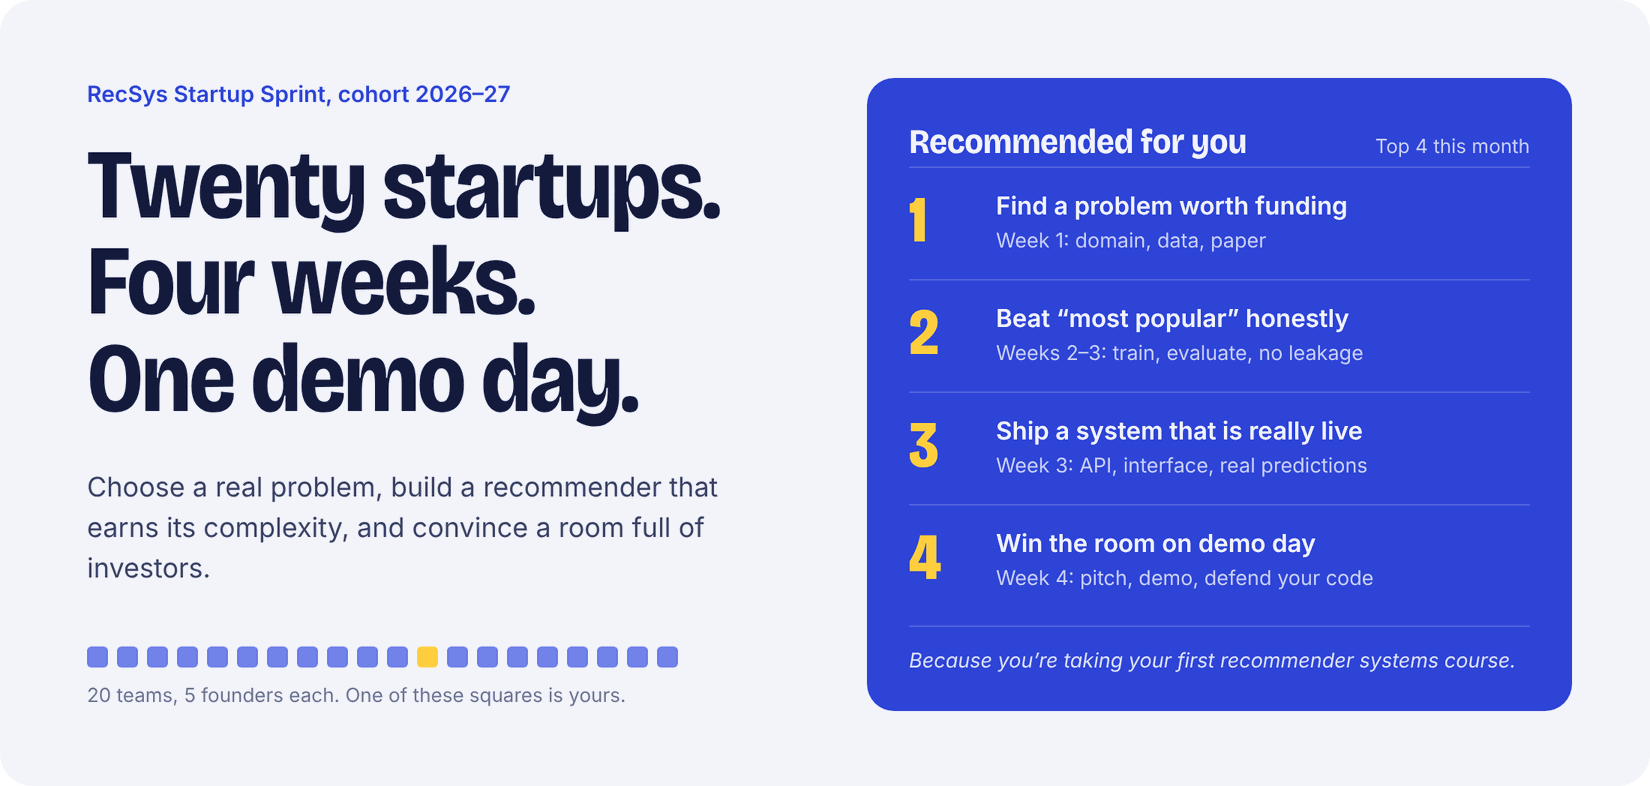

Alright, everyone. Welcome to the "RecSys Startup Sprint."

You've spent the last few years learning the theory. Now, you have **one month** to prove you're not just students, but engineers.

Your cohort of 20 groups will function as 20 competing startups. Your goal is to build, deploy, and demo a **Minimum Viable Product (MVP)** of an *innovative* recommender system, based on a concept from the RecSys papers I've provided.

Let me be clear. We are **not** building a simple baseline. I don't want to see another report on `k-NN` or standard `Matrix Factorization`. You are skipping straight to the advanced part. You will live or die by the quality of your GNN, your LLM, your context-aware model, or your fairness-enhanced algorithm.

This is a high-risk, high-reward strategy. It frees you from building a "control" model, but it means your evaluation must be *flawless*. You have nothing to hide behind. You must prove your complex model is actually learning, not just memorizing the most popular items.

And to make this real, you're not just convincing me. You're convincing your peers. At the end of this sprint, you will all vote for the best project. The top 3 teams, as decided by *your* peers, will receive a grade bonus. This is your "market validation."

Your focus is **80% on the algorithm, data, and evaluation, and 20% on the infrastructure.**

Finally, in a 5-person startup, *everyone* codes. There are no "project managers" who only make charts.

## 1. Team Roles: The "All-Hands-On-Deck" Crew

In your Week 1 Plan, you must assign these 5 roles. Everyone implements.

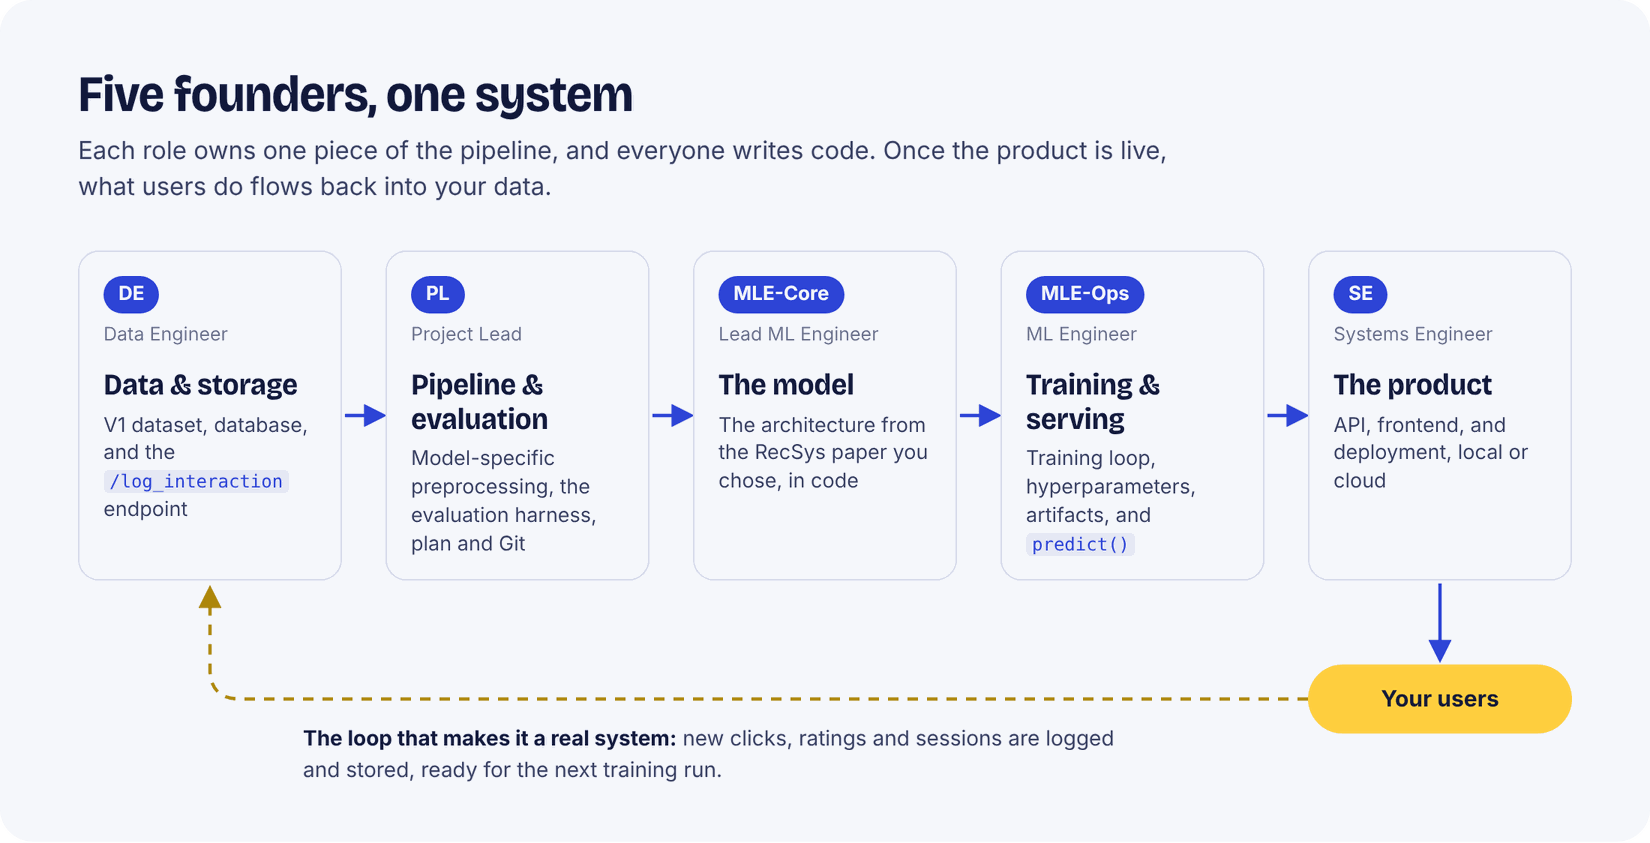

1.  **Project Lead (PL):** Manages the project plan, schedule, and repository (Git).
    * **Technical Responsibility:** Owns the **evaluation harness** and **model-specific data preprocessing**. They define the offline metrics ($NDCG@10$, $Recall@20$), write the testing script, and build the data-processing pipeline to feed the model (e.g., graph construction for a GNN).
2.  **Data Engineer (DE):** Owns the **data pipeline and storage**.
    * **Technical Responsibility:** Sources, cleans, and stores the V1 dataset. Builds the data-capture endpoint (e.g., `/log_interaction`) for new real-world interactions and the database (e.g., PostgreSQL, SQLite) to store them.
3.  **Lead ML Engineer (MLE-Core):** Owns the **core model implementation**.
    * **Technical Responsibility:** Implements the architecture from the chosen RecSys paper (e.g., the `PyTorch Geometric` implementation of the GNN).
4.  **ML Engineer (MLE-Ops):** Owns the **model training and serving logic**.
    * **Technical Responsibility:** Writes the training/validation loop, manages hyperparameters, saves model artifacts, and writes the core "predict" function that the API will call.
5.  **Systems Engineer (SE):** Owns the **full stack application**.
    * **Technical Responsibility:** Builds the `FastAPI`/`Flask` backend, the API endpoints, the `Streamlit`/`React` frontend, and manages the final deployment (local or cloud). See "Note on Deployment & Tech Stack" bellow.

## 2. The 4-Week Sprint: Plan, Build, Iterate, Demo

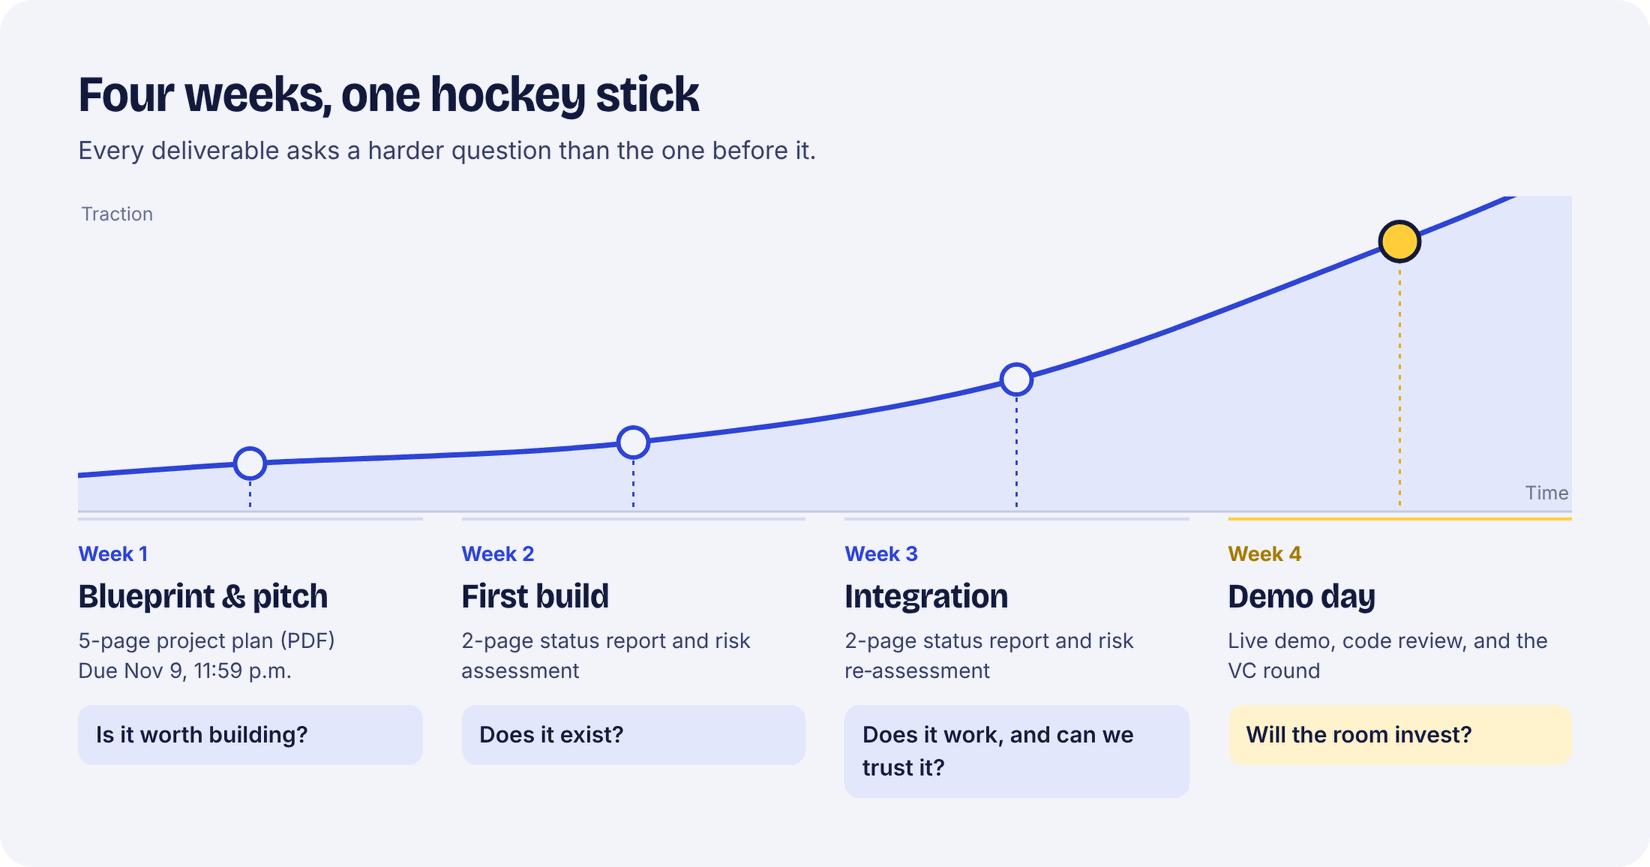

### Week 1: The Blueprint & The Pitch
**Deliverable:** A 5-page **Project Plan** (PDF) submitted before our next class, Deadline on **November $9^{th}$ at 11:59 p.m.**.

This is your roadmap. It *must* contain:

1.  **The "Startup" Team:** List your 5 members and their assigned roles.
2.  **The Problem & Domain:** What are you recommending, and to whom? You need to solve a *modern problem* that can attract investors to your startup.
    * **Choose your domain:** Be specific. (You can get inspiration from the RecSys Papers)
    * **Some examples of domains (do not limit yourselves to these domains):**

      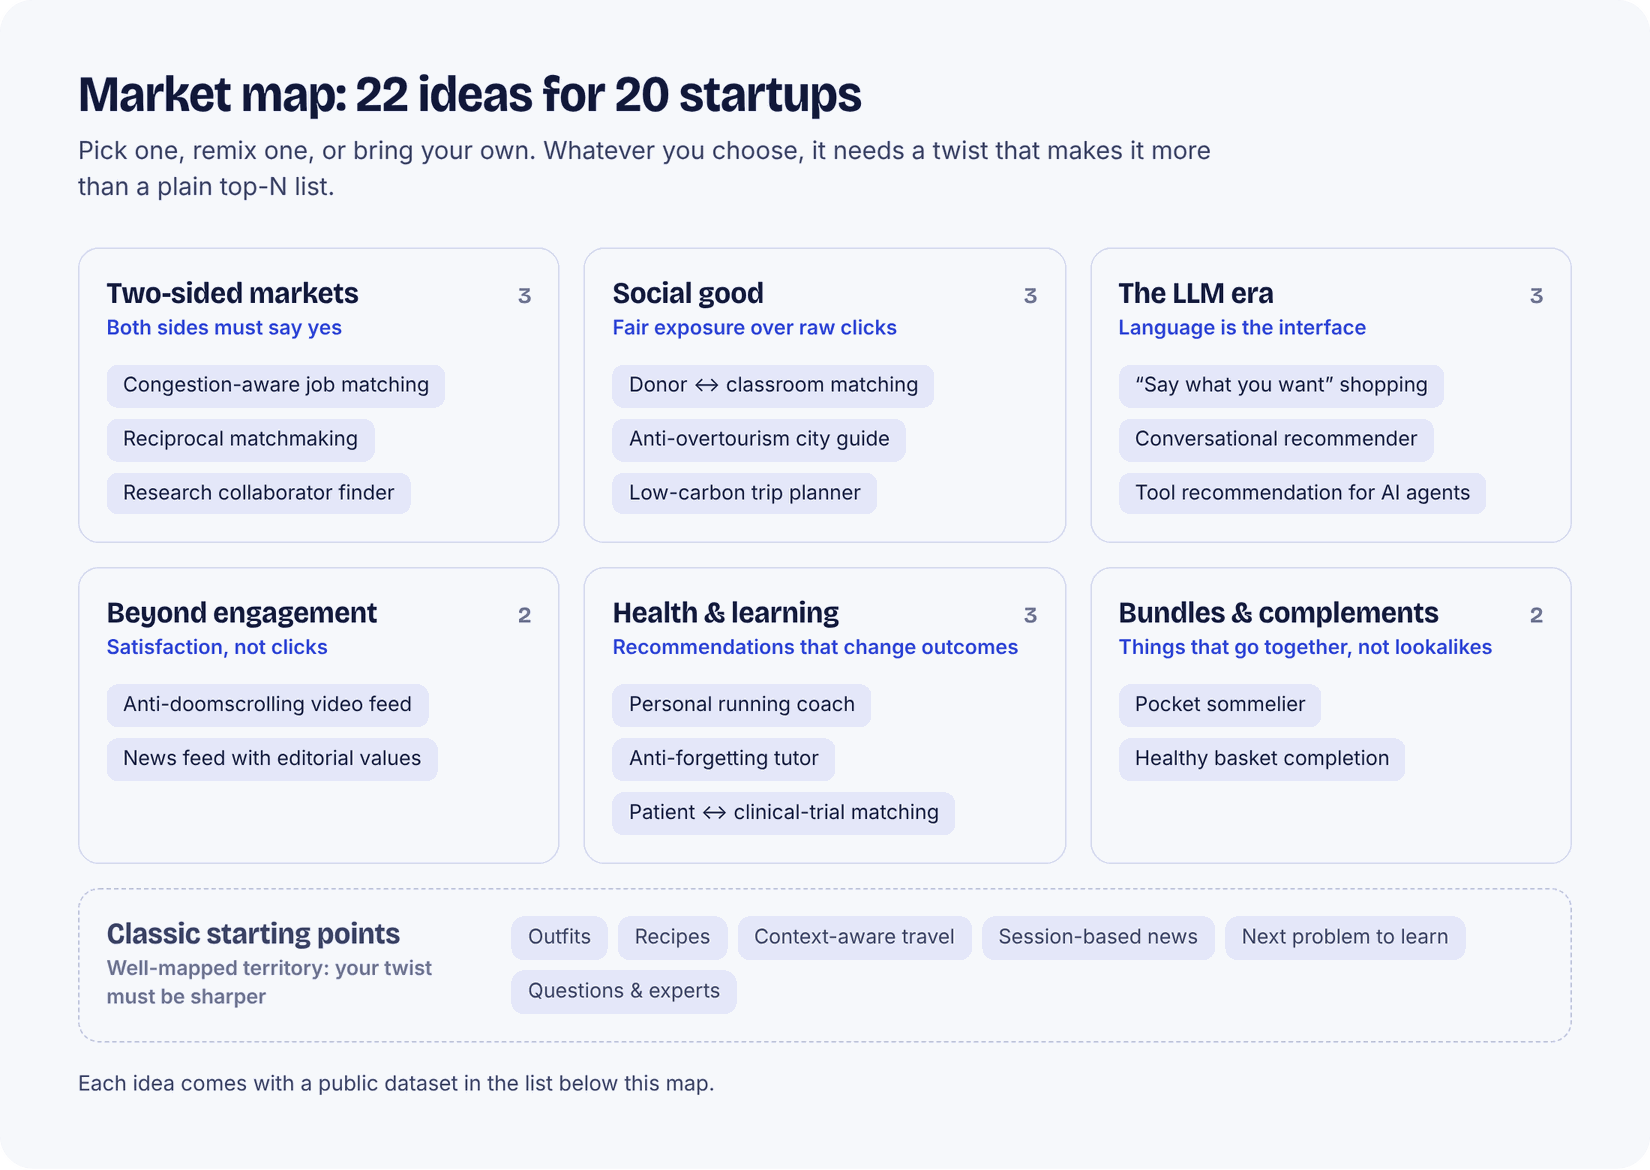

        * **Classic starting points**
            * Outfit Recommendation: [Polyvore Outfits](https://github.com/xthan/polyvore-dataset)
            * Recipe Recommendation: [Food.com - Recipes and Reviews](https://www.kaggle.com/datasets/irkaal/foodcom-recipes-and-reviews)
            * Context-Aware Travel: [Inside Airbnb](https://insideairbnb.com/get-the-data/)
            * Session-Based News Recommendation: [MIND](https://msnews.github.io/)
            * Recommend Next Problem to Maximize Learning: [EdNet](https://github.com/riiid/ednet)
            * Recommend relevant question / best experts: [Stack Overflow Data Dump](https://archive.org/details/stackexchange)
        * **Two-sided markets (both sides must benefit)**
            * Congestion-Aware Job Matching: recommend jobs a candidate wants *and* is qualified for, without sending every applicant to the same five employers. [CareerBuilder Job Recommendation](https://www.kaggle.com/c/job-recommendation)
            * Reciprocal Matchmaking (dating, co-founders, mentors): a match only counts if both people say yes. [Speed Dating Experiment](https://www.kaggle.com/datasets/annavictoria/speed-dating-experiment) (small: ~550 participants)
            * Research Collaborator Finder: "who should you co-author with next?", rewarding interdisciplinary links over the usual collaborators. [OpenAlex](https://openalex.org)
        * **Recommendation for social good**
            * Donor ↔ Classroom Matching: give visibility to under-funded projects from poorer schools, not only the ones already going viral. [DonorsChoose - Data Science for Good](https://www.donorschoose.org/data)
            * Anti-Overtourism City Guide: recommend hidden gems instead of the Eiffel Tower, with fair exposure for lesser-known places. [Foursquare NYC/Tokyo Check-ins](https://sites.google.com/site/yangdingqi/home/foursquare-dataset), [Yelp Open Dataset](https://www.yelp.com/dataset)
            * Low-Carbon Trip Planner: recommend the next destination of a multi-city trip, re-ranked for CO₂ (train-reachable cities first). [Booking.com Multi-Destination Trips](https://github.com/bookingcom/ml-dataset-mdt) (non-commercial license)
        * **Beyond engagement**
            * Anti-Doomscrolling Video Feed: optimize for satisfaction (long views, likes, explicit dislikes) instead of raw clicks. Randomly exposed videos make unbiased offline evaluation possible. [KuaiRand](https://kuairand.com), and its sibling [KuaiRec](https://kuairec.com) with a fully observed user–item matrix.
            * News Feed with Editorial Values: accuracy *and* diversity, not just crime and celebrity stories. [EB-NeRD](https://recsys.eb.dk) (RecSys Challenge 2024)
        * **Problems from the LLM era**
            * "Say What You Want" Shopping: the user describes a need in plain language ("a gift for my dad who loves fishing but hates gadgets") and gets ranked products. [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/)
            * Conversational Recommender: a chatbot that asks the right questions before recommending a movie. [ReDial](https://redialdata.github.io/website/)
            * Tool Recommendation for AI Agents: the "user" is an LLM agent; recommend which of thousands of real APIs it should call for a task. [ToolBench](https://github.com/OpenBMB/ToolBench)
        * **Health & learning**
            * Personal Running Coach: recommend the workout route or sport and a target pace from heart-rate sequences. [Endomondo / FitRec](https://cseweb.ucsd.edu/~jmcauley/datasets.html#endomondo)
            * Anti-Forgetting Tutor: recommend which word to review now, before it is forgotten (spaced repetition as recommendation). [Duolingo Half-Life Regression](https://github.com/duolingo/halflife-regression)
            * Patient ↔ Clinical-Trial Matching: an LLM reads a patient description and ranks the trials whose eligibility criteria fit. [TREC Clinical Trials Track](https://www.trec-cds.org/)
        * **Bundles & complements**
            * Pocket Sommelier: wine recommendation with food pairing (complementary items, not similar ones). [X-Wines](https://github.com/rogerioxavier/X-Wines)
            * Healthy Basket Completion: complete the grocery basket while nudging toward healthier swaps. [Instacart Market Basket](https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis)
3.  **Data Strategy:** Your V1 dataset and your plan for capturing *new* interaction data.
4.  **The "Innovation" (The Core Task):** 
    * The **RecSys paper** you've chosen and the core concept you will implement. You need to cite the paper and explain it briefly.
    * For instance if you choose to implement a GNN-based model. Your innovation could be:
        * Context-Awareness: Augmenting your GNN with temporal data (time of day) or session-based features.

        * Fairness/Diversity: Implementing a re-ranking layer on top of your model's output to mitigate popularity bias.

        * Explainability: Using the GNN's attention weights or learned embeddings to provide a simple explanation (e.g., "Because you liked...").

        * Hybridization: Fusing your GNN (collaborative) with a content-based model (e.g., using item descriptions) for cold-start users.
5.  **Technical Stack:** Your chosen libraries, frameworks, and database.
6.  **Schedule & Task Breakdown:** A detailed week-by-week plan.

### Week 2: The First Build
**Deliverable:** A 2-page **Status Report** & **Risk Assessment**.

Your report must include:
1.  **Progress Update:** What tasks are "Done," "In Progress," or "Blocked"?
2.  **Risk Assessment:** You must answer these five questions and declare your risk level (**Low, Medium, High**).
    * **Q1 (Data):** Is your V1 data pipeline built, and have you successfully processed your entire initial dataset? (Yes/No)
    * **Q2 (Model):** Is the code skeleton for your *innovative* algorithm built, and can you successfully run one forward pass without it crashing? (Yes/No)
    * **Q3 (Evaluation):** Is your evaluation harness built?  (i.e., can you feed it mock predictions and get a metric like $NDCG$ back?) (Yes/No)
    * **Q4 (System):** Is your backend API defined and able to return *mock* recommendations? (Yes/No)
    * **Q5 (Schedule):** Are you on, ahead of, or behind your Week 1 schedule?

**Risk Level Calculation:**
* **Low:** 0 "No" answers.
* **Medium:** 1-2 "No" answers or "Behind Schedule." (You need a plan to catch up).
* **High:** 3+ "No" answers. (You are in significant trouble).

### Week 3: Integration & Iteration
**Deliverable:** A 2-page **Status Report** & **Risk Re-assessment**.

The system should be *alive* this week. Your report must include:
1.  **Progress Update:** Same as Week 2.
2.  **Key Results:**
    * A plot of your training/validation loss curves. Did it converge?
    * Your final offline evaluation metrics (e.g., $NDCG@10$).
    * **Qualitative Sanity Check:** Show 3 sample users and their recommendations. Explain *why* they prove your model is working (e.g., "Note the high diversity, it's not just showing popular items").
3.  **Live System:** A screenshot of your working interface.
4.  **Risk Re-assessment:** Week 2 checked whether your components *exist*. Week 3 checks whether they *work* and whether your results can be *trusted*. You must answer these questions and declare your risk level (**Low, Medium, High**).
    * **Q1 (Training):** Has your innovative model been trained on the full V1 dataset, with training/validation curves that converge (no NaNs, no divergence, validation loss not rising after the first epochs)? (Yes/No)
    * **Q2 (Sanity Floor):** Using the same test split and the same evaluation harness, does your model beat a *random* ranking and a *most-popular* ranking on $NDCG@10$ and $Recall@20$? (Yes/No) *This is not a control model: a most-popular ranking takes five lines of code, and it is the simplest proof that your model is not just memorizing popular items.*
    * **Q3 (Leakage):** Is your evaluation free of leakage? Test interactions must never be used for training, graph construction, feature or embedding computation, or hyperparameter tuning. If your data has timestamps, your split must be temporal or leave-last-out. (Yes/No)
    * **Q4 (Innovation Proof):** Have you measured your innovation with its own metric (e.g., coverage/diversity, exposure fairness, cold-start $NDCG$, explanation fidelity) **and** run an ablation, i.e., the same model with the innovative component switched off? (Yes/No)
    * **Q5 (Live System):** Does your system serve real predictions end-to-end? The frontend calls the API, the API calls the trained model (no mocks), the response arrives in under ~2 seconds, and an interaction sent to `/log_interaction` appears in the database. (Yes/No)
    * **Q6 (Reproducibility):** Has a team member who did not write the code cloned the repository on a clean machine and launched the system in under 10 minutes using only the `README.md`? (Yes/No)
    * **Q7 (Schedule):** Are you on, ahead of, or behind your schedule? List what remains to be done before the showcase.

**Evidence Rule:** Every "Yes" must point to evidence in your report (a plot, a metrics table, a screenshot, or a commit hash). A "Yes" without evidence counts as a "No."

**Risk Level Calculation** (stricter than Week 2: the showcase is one week away):
* **Low:** 0 "No" answers and on schedule.
* **Medium:** 1 "No" answer or "Behind Schedule." (You need a plan to catch up).
* **High:** 2+ "No" answers. (You are in significant trouble).

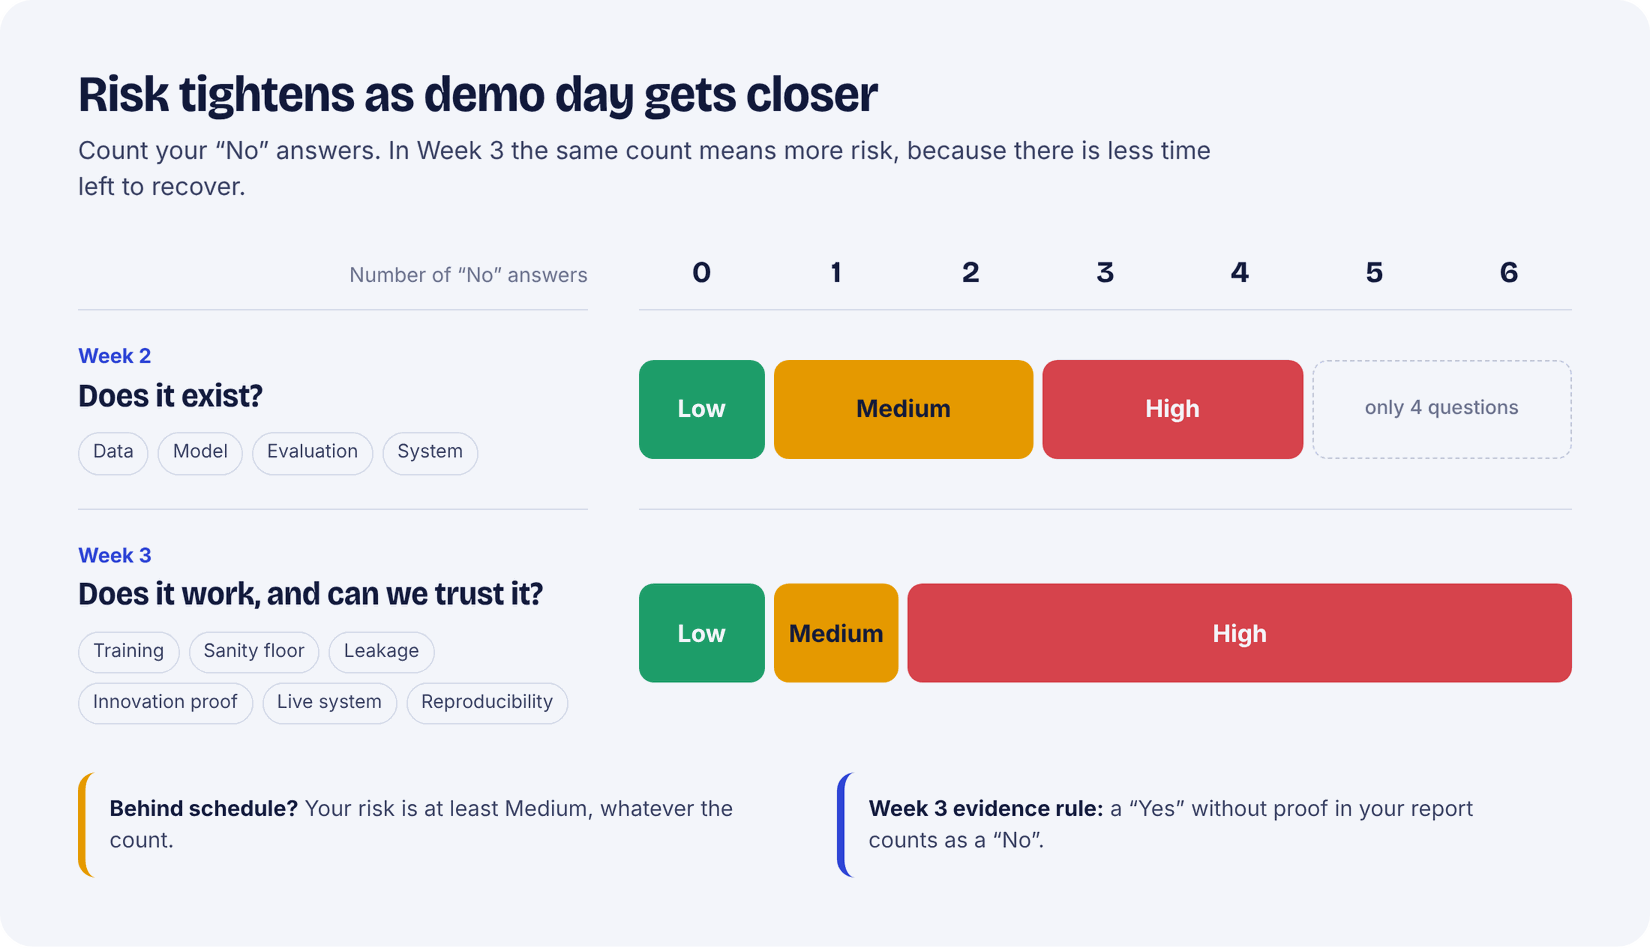

### Week 4: The Startup Showcase & VC Fund
#### *Overview*
This final event is the culmination of your project. We will simulate a "Startup Showcase & VC Fund" where you will present your project as a startup seeking investment. You will also act as a Venture Capitalist (VC), evaluating and investing in other teams' projects. <br>
The class is split into two sessions: **Groups 1-10** will present in the morning, and **Groups 11-20** will present in the afternoon. When you are not presenting, you are an investor.

#### *Event Schedule*

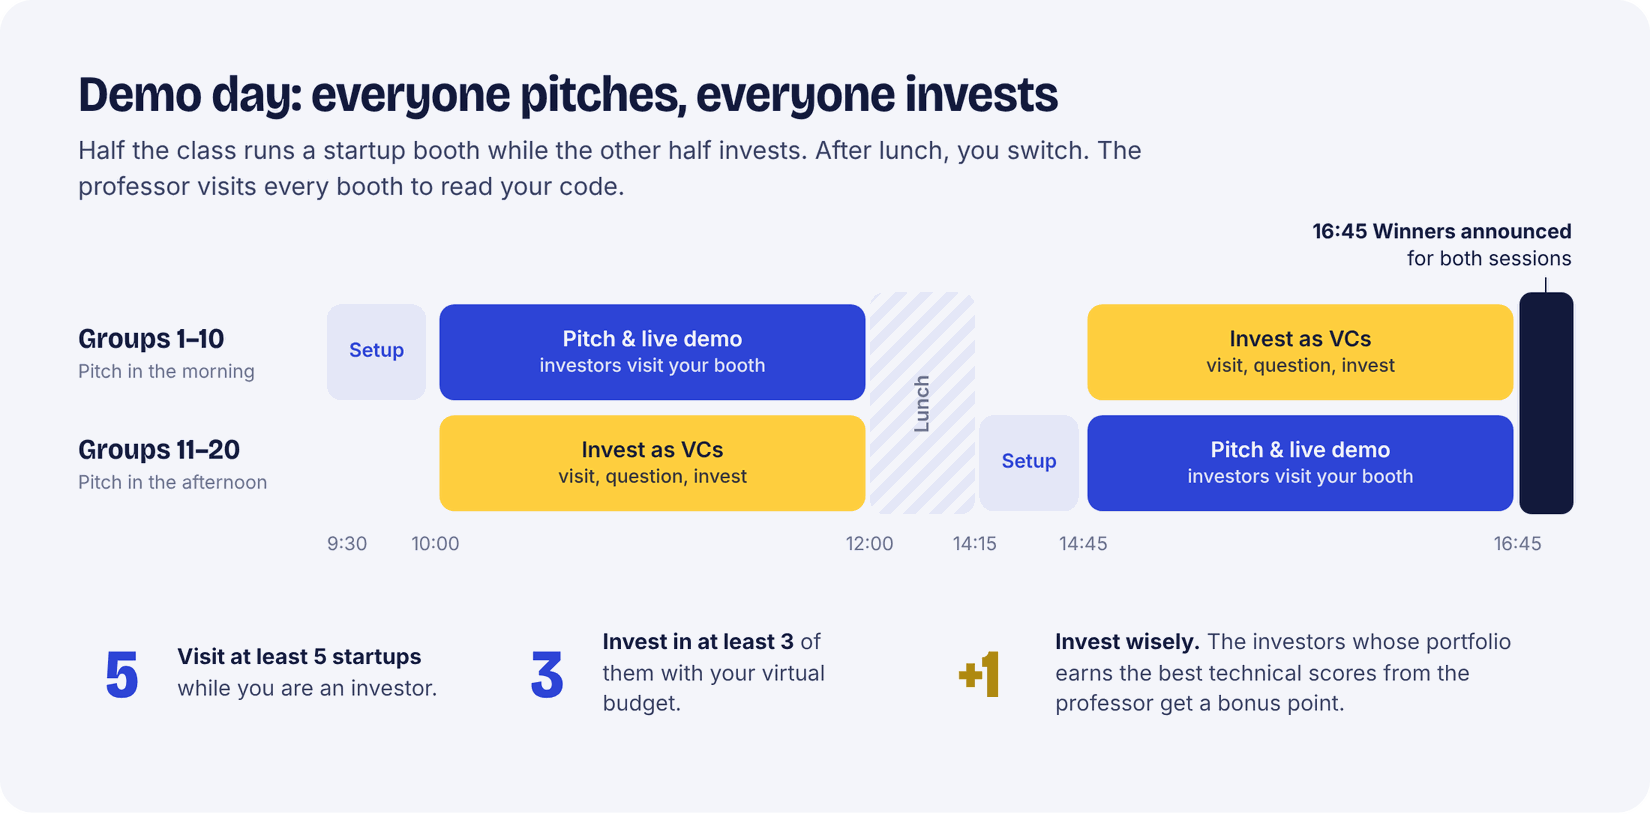

**Morning Session (Groups 1-10 Presenting)**
*    **9:30 - 10:00:** Setup for Groups 1-10. Arrive, set up your laptops, posters, and any other materials.
*    **10:00 - 12:00:** Showcase & Investment. The room opens. Investors (Groups 11-20) arrive and begin visiting. Professor evaluation also takes place during this time.
*    **12:00:** Morning session concludes.

**Afternoon Session (Groups 11-20 Presenting)**
*    **14:15 - 14:45:** Setup for Groups 11-20.
*    **14:45 - 16:45:** Showcase & Investment. Investors (Groups 1-10) arrive and begin visiting. Professor evaluation also takes place.
*    **16:45 - 17:00:** **Winner Announcement** (for all groups).
*    **17:00:** Tidy up the classroom.

#### *Roles & Objectives*

**1.  Startups (Your Presentation Session)**
Your goal is to convince investors (your peers) and the evaluator (me) of your project's value.
*    **Pitch:** Clearly explain your project's core innovation and value proposition.
*    **Demonstrate:** Be prepared to give a live demo of your system and **show your code**.
*    **Defend:** You must answer technical questions from me and strategic questions from investors.
*    **Logistics:** Each group will have a dedicated space in the classroom. You will be given a unique **QR code** that investors will scan to "invest" in your project.

**2.  Investors (Your Non-Presentation Session)**
Your goal is to act as an expert VC . You will be given a virtual budget to allocate.
*    **Mandatory Visits:** You **must** visit at least 5 different startups.
*    **Mandatory Investments:** You **must** invest in at least 3 different startups.
*    **Goal:** Optimize your portfolio. Invest wisely in the projects you believe have the highest technical quality, innovation, and potential for success.

**3.  Professor (Evaluator)**
I will act as a technical evaluator, not an investor.
*    My goal is to visit every group to ask in-depth questions.
*    I will **check your code**, evaluate the correctness of your system, and assess the overall coherence of your project from a technical standpoint.

#### *How to Prepare Your "Startup"*
This is your chance to sell your project.
*    **Dress the Part:** This is a professional showcase. Dress to convince investors you are serious about your innovation.
*    **Valorize Your Innovation:** Don't just describe what your system does; explain why it matters. What makes it new or better?
*    **Visuals are Key:** You are strongly encouraged to use visuals to support your pitch:
     * A running demo on your laptop.
     * Slides, images, or even short videos.
*    **Handouts (Optional):** You can prepare a simple one-page flyer or "executive summary" to give to investors to help them remember your project.

## 3. Grading Breakdown (20 Points)

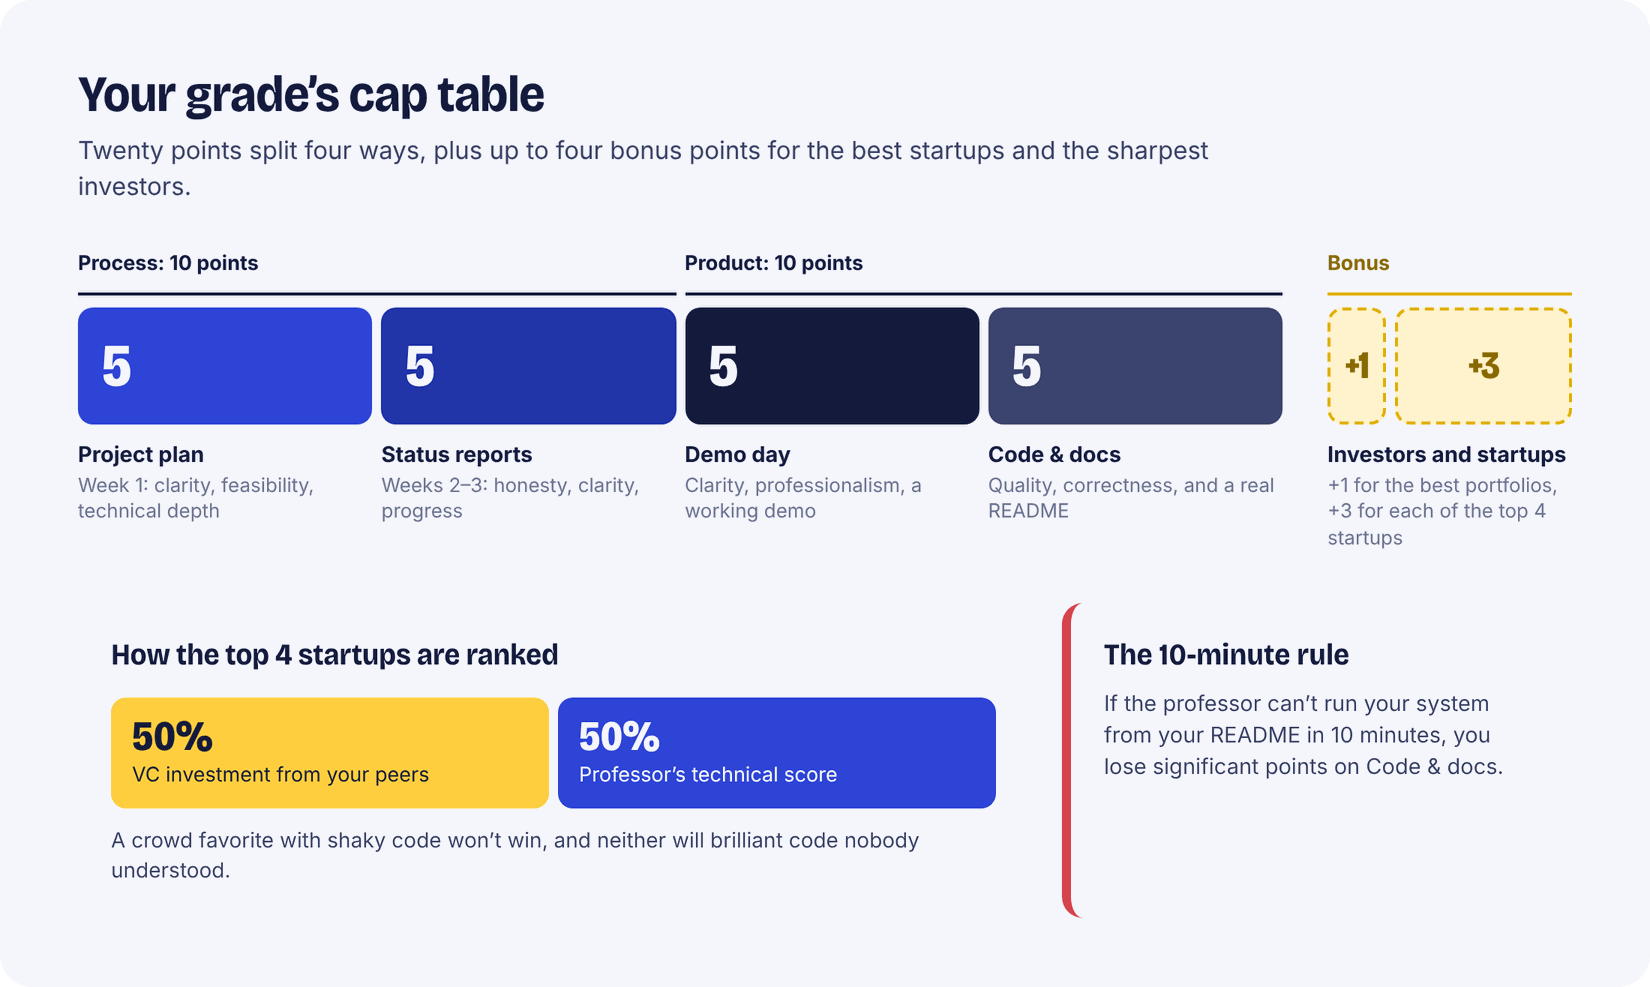

Your grade is split 50/50 between your process and your final product + the bonus points.

#### **A. The Process (10 points)**
* **Week 1 Project Plan:** (5 points) Graded on clarity, feasibility, and technical depth.
* **Week 2 & 3 Status Reports:** (5 points) Graded on honesty, clarity, and the progress you demonstrate.

#### **B. The Product (10 points)**
* **Final Presentation & Demo:** (5 points) Graded on clarity, professionalism, and a *working* demo.
* **Code & Documentation (GitHub):** (5 points) Graded on code quality, correctness, and—critically—your documentation.

**Final Code Repository Requirements:**
I *will* run your code. Your repository must contain:
* All source code for your model, API, and frontend.
* A `requirements.txt` (or `environment.yml`) file.
* A **`README.md`** file that is *not* an afterthought. It must contain:
    * A brief project description and team members.
    * A clear, step-by-step guide on how to **run your system locally**. (e.g., `1. clone repo`, `2. create venv`, `3. pip install -r requirements.txt`, `4. run python app.py`, `5. open http://localhost...`).
    * Instructions on how to (optionally) re-train your model.

If I cannot get your project running locally in 10 minutes following your `README`, you will lose significant points on this component. This is non-negotiable.

#### **C. Bonus Points**
Your final project grade is based on the technical quality of the work, but you can earn significant bonuses during the showcase.

**Bonus 1: The Top Investors (+1 Point)**
*    The investors who best optimize their virtual money will receive a **+1 point bonus**.
*    **How this is judged:** The "best" investors are those whose chosen portfolio (the startups they invested in) has the highest average technical score from the professor. This rewards genuine technical insight, not just following the crowd.

**Bonus 2: The Top 4 Startups (+3 Points)**
*    The top 4 startups will receive a +3 point bonus.

**How "Top Startups" are Chosen** To ensure the best projects win (not just the most popular groups), the final startup ranking will be based on a combined score. This balances popular appeal with technical quality. <br>
    Final Rank = 50% (Total VC Investment Received) + 50% (Professor's Technical Score)

A project needs both strong peer support and high technical quality to win.

Good Luck!

# 4. A Note on Deployment & Tech Stack

The goal is an end-to-end system, but the algorithmic innovation is the priority.

* **Cloud (Preferred):** This is the most "real-world" experience.
    * **Platforms:** `Google Cloud Run` (has a generous free tier for serverless containers), `Heroku` (free/hobby tier), `AWS Educate` / `Azure for Students` (use your student credits).
    * A `FastAPI` + `GCP Cloud Run` + `Cloud SQL` is a powerful, low-cost stack.

* **Local (100% Acceptable Fallback):** If you spend more than 2-3 days on cloud configuration, abandon it.
    * A **local server-client architecture** is perfectly fine.
    * **Example:** The Systems Engineer runs the `FastAPI` server on their machine. Another student opens a browser on a different machine on the same WiFi and accesses the server via its local IP (e.g., `http://192.168.1.10:8000`). This proves the system architecture works without the headache of cloud IAM roles.